# Run this to enable loading from relative packages

In [1]:
%load_ext autoreload
%autoreload 2
if "PKG" not in globals():
  import importlib, sys, pathlib # https://stackoverflow.com/a/50395128/11996983
  PKG = %pwd
  PKG = pathlib.Path(PKG)
  root_parent_level = 2
  root = PKG
  full_pkg = f"{root.name}"
  for _ in range(root_parent_level):
    root = root.parent
    full_pkg = f"{root.name}.{full_pkg}"
    MODULE_PATH = str(root / "__init__.py")
    MODULE_NAME = f"{root.name}"
    spec = importlib.util.spec_from_file_location(MODULE_NAME, MODULE_PATH)
    module = importlib.util.module_from_spec(spec)
    sys.modules[spec.name] = module
    spec.loader.exec_module(module)
  __package__ = full_pkg


In [2]:
# Papermill parameters -- code/run_notebooks.py overrides these.
# Everything is off by default, so running the notebook writes nothing.
SAVE_FIGS = False           # write figures under results/
SAVE_DATA = False           # rewrite cached intermediate data under data/
PAPER_FIGURES_ONLY = False  # skip per-subject / per-session figures

# Figure 7D's surface (see model/qrsurface.py for why these exist):
RESAMPLE_COUNT = 1_000      # pseudo-sessions per real session
NUDGE_LATENT_SD = 0.01      # per-trial jitter on Q and the reward rate
SURFACE_WORKERS = 10        # subjects simulated in parallel; each needs ~3-4 GiB


# Save plots with no embedded fonts

In [4]:
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']


# Figures Save Path

In [5]:
save_prefix = r"../../results/RLModel/"
import pathlib
try:
    pathlib.Path(save_prefix).mkdir(exist_ok=True)
except:
    print("Failed to create save dir...")

# Load model fitting

In [6]:
from pathlib import Path

# Figure 7D reads one fit: the chi-squared 4.8 s fit.
# qrsurface loads it through model.fitio, which rebuilds the bias/drift/noise
# functions the fits store by registry name -- a plain pickle.load hands back
# the names and the simulation then refuses to run.
KEY = "chisq_NoiseGain-RewardRate_biasQ-Val (Offset)_Normal(0, 1)_4.8s_dt0.005.pkl"
FIT_PATH = Path("../../data/RLModel") / KEY
assert FIT_PATH.is_file(), f"missing fit: {FIT_PATH}"

# Fit data and resample if required

In [7]:
from .model import qrsurface

# Resample each subject into pseudo-sessions with fresh stimulus strengths,
# simulate them under that subject's fitted parameters, and bin the result.
# One subject per worker, and only per-facet sums come back, so the full
# resample count takes ~10 min and a few GiB per worker.
#
# 1,000 resamples over 272 sessions is 272,000 pseudo-sessions.
qr_grids = qrsurface.simulate(FIT_PATH, resample_count=RESAMPLE_COUNT,
                              nudge_sd=NUDGE_LATENT_SD,
                              workers=SURFACE_WORKERS)
print(f"{qr_grids['trials']:,} correct trials from "
      f"{len(qr_grids['subjects'])} subjects")

47,836,186 correct trials from 22 subjects


## As Surface Plot

In [8]:
%matplotlib inline
# %matplotlib widget # Enable for interactive plots

## Figure 7D

facet counts: (10, 20, 3)  - max: 1930236.0


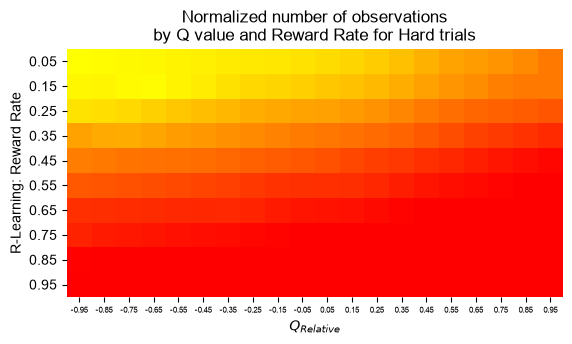

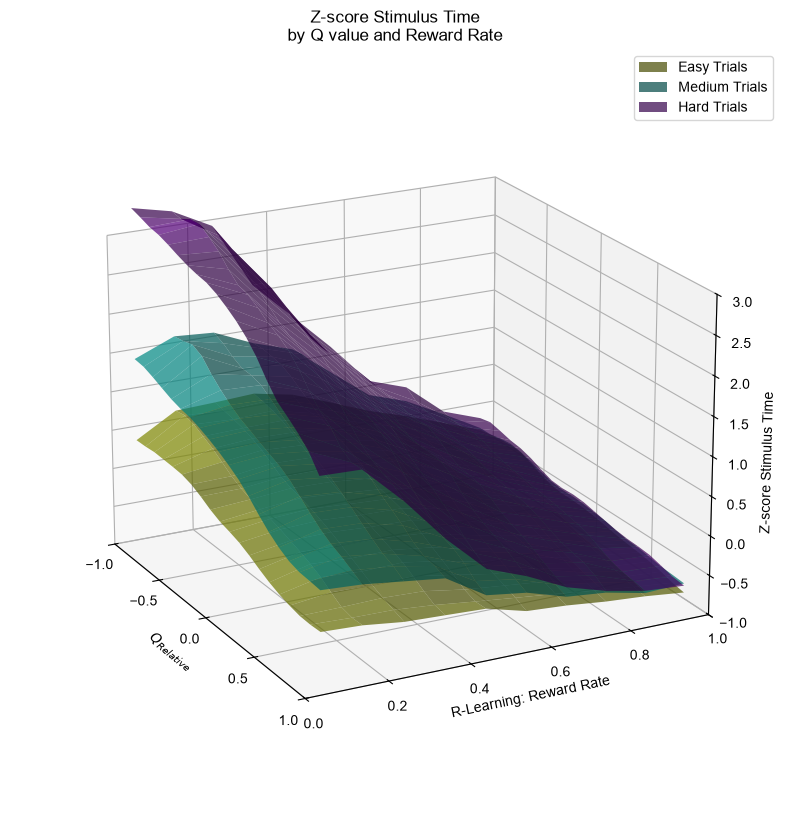

In [9]:
from ..common.clr import Difficulty as DifficultyColor
from ..pipeline.utils import filterNanGaussianConserving
from .model import qrsurface
import matplotlib.pyplot as plt
import numpy as np


def plotQ_R_Heatmap(grids, save_figs=False, balanced=True):
    """Figure 7D. ``grids`` comes from qrsurface.simulate.

    Three choices shape the surface, each argued and measured in
    model/qrsurface.py:

    - reward-rate-0 trials are binned at 0 (not wrapped to 1.0), and facets
      are plotted at bin centres rather than edges;
    - each facet averages per-subject means, so a facet cannot be one animal
      (pooling trials makes the Q -0.7..-0.6 column 97% one mouse, which puts
      a trough in the Medium and Easy sheets);
    - the latents carry a small per-trial nudge, because the fitted learning
      rates leave Q on a lattice that the bins alias.
    """
    surface = grids["balanced"] if balanced else grids["pooled"]
    counts = grids["counts"]
    MIN_NUM_OBSERV = 1
    surface = np.where(counts > MIN_NUM_OBSERV, surface, np.nan)
    print("facet counts:", counts.shape, " - max:", counts.max())

    smoothed = filterNanGaussianConserving(surface, sigma=1.0, axis=1)
    q_centres = qrsurface.binCentres(qrsurface.Q_EDGES)
    rr_centres = qrsurface.binCentres(qrsurface.RR_EDGES)

    fig_hist, ax_imshow = plt.subplots()
    norm_observ = smoothed[:, :, 0].astype(float) / np.nanmax(smoothed[:, :, 0])
    ax_imshow.imshow(norm_observ, cmap="autumn", vmin=0, vmax=1)
    ax_imshow.set_xticks(np.arange(q_centres.size))
    ax_imshow.set_xticklabels([f"{c:.2g}" for c in q_centres], fontsize=6)
    ax_imshow.set_yticks(np.arange(rr_centres.size))
    ax_imshow.set_yticklabels([f"{c:.2g}" for c in rr_centres])
    ax_imshow.set_xlabel("$Q_{Relative}$")
    ax_imshow.set_ylabel("R-Learning: Reward Rate")
    ax_imshow.set_title("Normalized number of observations\n"
                        "by Q value and "
                        "Reward Rate for Hard trials")
    ax_imshow.spines[["top", "right", "bottom", "left"]].set_visible(False)
    plt.show()

    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={"projection": "3d"})
    X, Y = np.meshgrid(q_centres, rr_centres)
    for color, data, name in [(DifficultyColor.Easy, smoothed[:, :, 2], "Easy"),
                              (DifficultyColor.Med, smoothed[:, :, 1], "Medium"),
                              (DifficultyColor.Hard, smoothed[:, :, 0], "Hard")]:
        ax.plot_surface(X, Y, data, color=color, alpha=0.7, rstride=1, cstride=1,
                        linewidth=0, antialiased=True, label=f"{name} Trials")
    ax.legend()
    ax.set_xticks(np.arange(-1, 1.25, 0.5))
    ax.set_xlabel("$Q_{Relative}$")
    ax.set_ylabel("R-Learning: Reward Rate")
    ax.set_zlabel("Z-score Stimulus Time")
    ax.set_title("Z-score Stimulus Time\nby Q value and Reward Rate")
    ax.set_xlim(-1, 1)
    ax.set_ylim(0, 1)
    ax.set_zlim(-1, 3)
    ax.view_init(azim=-27.5, elev=20,)
    ax.set_box_aspect(aspect=None, zoom=.9)
    if save_figs:
        fig.savefig(f"{save_prefix}/Q_R_Heatmap.svg", dpi=300,
                    bbox_inches='tight')
    plt.show()


plotQ_R_Heatmap(qr_grids, save_figs=SAVE_FIGS)